In [1]:
import numpy as np
import pandas as pd
import sys
import helpers as hp
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import roc_auc_score, accuracy_score

In [2]:
# 1. npz 파일에서 임베딩 벡터와 ID 배열 로드
embeddings_data = np.load('Project3/starfield_embeddings2.npz')
X_raw = embeddings_data['embeddings']                  # (72061, 1024)
embedding_ids_raw = embeddings_data['recommendationid']  # (72061,)

# 2. 원본 CSV 로드 (DtypeWarning 방지 옵션 추가)
df_raw = pd.read_csv('Project3/df_ready.csv', low_memory=False)


# 3. 임베딩 ID와 인덱스를 매핑할 데이터프레임 생성
# (나중에 임베딩 벡터 X를 필터링하기 위해 원본 임베딩의 행 번호(emb_idx)를 기록해둡니다)
df_emb_map = pd.DataFrame({
    'recommendationid': embedding_ids_raw,
    'emb_idx': np.arange(len(embedding_ids_raw))
})

# CSV 기준으로 병합 (how='inner'를 사용하면 CSV와 임베딩 양쪽에 모두 존재하는 것만 남습니다)
df = pd.merge(df_raw, df_emb_map, on='recommendationid', how='inner')

# 병합 결과로 살아남은 행 번호들만 추출하여 임베딩 데이터 필터링
valid_indices = df['emb_idx'].values
X = X_raw[valid_indices]
embedding_ids = embedding_ids_raw[valid_indices]

# 임베딩 행 번호 컬럼은 더 이상 필요 없으므로 삭제
df = df.drop(columns=['emb_idx'])

# 4. 정렬 정합성 최종 검증
print("최종 CSV 행 개수:", len(df))
print("최종 임베딩(X) 행 개수:", X.shape[0])

# 5. 기존 분석 코드 전처리 이어하기
y = df.voted_up.astype(int).values      # 0 / 1 로 변환
df['review'] = df.review.astype(str)    # 에러방지용 str 타입 변환
df['len'] = df.review.str.len()         # 글자수(길이) 컬럼 생성 -> 단문, 장문 리뷰 구분용
idx = np.arange(len(df))                # 인덱스 배열 생성(원본 df와 임베딩벡터X 매칭을 유지하면서 행번호만 쪼개기위해)

print('| 긍정률 %.3f' % y.mean())       # 1(추천) 비율

# 품질 점검
display(hp.my_qtcheck.check_missing_values(
    df[['recommendationid', 'language', 'voted_up', 'stage_at_review', 'review']]))


최종 CSV 행 개수: 70915
최종 임베딩(X) 행 개수: 70915
| 긍정률 0.572


,Missing Count,Missing Ratio (%)
recommendationid,0,0.0
language,0,0.0
voted_up,0,0.0
stage_at_review,0,0.0
review,0,0.0


In [3]:
df.head()

,recommendationid,language,review,ts_created,ts_updated,voted_up,votes_up,steam_purchase,received_for_free,refunded,...,last_played,month,stage_final,n_ach_total,first_unlock,last_unlock,stage_at_review,n_ach_at_review,gap_days,len
0,145736013,english,"Wide as a lake, deep as a puddle.",2023-09-06 00:00:29,2023-12-23 21:49:27,False,1,True,False,False,...,2026-04-14 17:29:47,2023-09,2,19,2023-09-01 12:02:37,2023-09-21 02:24:41,2,7,936.628542,33
1,145736016,english,Starfield is a Bethesda RPG through and throug...,2023-09-06 00:00:30,2023-09-16 22:15:56,True,1,False,False,False,...,2026-08-31 19:19:03,2023-09,10,82,2023-09-01 10:47:58,2026-05-18 10:38:42,10,28,105.361354,1021
2,145736021,russian,"Скайрим с пушками. Что, уже был такой? Ну тогд...",2023-09-06 00:00:31,2023-09-11 04:14:39,True,1,True,False,False,...,2023-11-25 10:37:58,2023-09,3,25,2023-09-01 03:46:30,2023-10-01 21:30:30,2,6,54.546852,385
3,145736025,schinese,依托臭构式,2023-09-06 00:00:32,2023-11-02 16:11:03,False,1,False,False,False,...,2023-09-01 09:52:21,2023-09,2,2,2023-09-01 01:08:47,2023-09-01 02:15:01,2,2,0.317593,5
4,145736030,english,Bethesda should be called Bugthesda !,2023-09-06 00:00:32,2023-09-06 00:00:32,True,0,False,False,False,...,2024-09-11 15:18:55,2023-09,10,31,2023-09-01 12:21:30,2023-11-19 17:44:45,3,11,296.898727,37


In [4]:
print("CSV 행 개수:", len(df))
print("임베딩(X) 행 개수:", X.shape[0])

CSV 행 개수: 70915
임베딩(X) 행 개수: 70915


In [5]:
embeddings_data = np.load('Project3/starfield_embeddings.npz')
print("npz에 저장된 키 목록:", embeddings_data.files)

npz에 저장된 키 목록: ['embeddings', 'recommendationid']


In [6]:
from sklearn.model_selection import StratifiedKFold
import numpy as np
import pandas as pd

# 1. OOF 및 테스트 예측을 위한 배열 초기화
n_splits = 5  # 5-Fold 교차 검증
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=hp.RANDOM_STATE)

# 전체 데이터 개수만큼 0으로 채워진 OOF 배열 생성 (각 행의 검증 예측값이 담김)
oof_preds = np.zeros(len(df))

print(f"=== {n_splits}-Fold OOF 학습 및 예측 시작 ===")

# 2. K-Fold 루프 돌며 학습 및 검증 세트 예측
# (y를 기반으로 층화 분할하므로 언어 불균형으로 인한 에러를 방지합니다)
for fold, (train_idx, val_idx) in enumerate(skf.split(idx, y)):
    print(f"▶ Fold {fold + 1}/{n_splits} 학습 중...")
    
    # 기존 fit_eval의 로직을 폴드별 train/val에 적용
    # X가 대용량 임베딩 벡터(1024차원)이므로 solver='saga', n_jobs=None 적용
    Xa_train = X[train_idx]
    Xa_val = X[val_idx]
    
    m = LogisticRegression(
        solver='saga', 
        max_iter=300, 
        tol=1e-3, 
        n_jobs=None, 
        random_state=hp.RANDOM_STATE
    ).fit(Xa_train, y[train_idx])
    
    # 검증 세트(val_idx)에 대한 예측 확률을 OOF 배열의 해당 위치에 기록
    oof_preds[val_idx] = m.predict_proba(Xa_val)[:, 1]

print("=== OOF 학습 완료 ===")

# 3. OOF 최종 성능 평가 (전체 데이터에 대한 AUC와 Accuracy)
from sklearn.metrics import roc_auc_score, accuracy_score

oof_auc = roc_auc_score(y, oof_preds)
oof_acc = accuracy_score(y, (oof_preds >= 0.5).astype(int))
print('\n[OOF 최종 결과] AUC %.4f | Acc %.4f' % (oof_auc, oof_acc))

# ==================== [핵심: 원본 df에 OOF 결과 연결] ====================

# 4. 원본 df에 예측 확률과 예측 라벨을 컬럼으로 직접 추가 (행 개수가 1:1로 정확히 일치)
df['oof_pred_proba'] = oof_preds
df['oof_pred_label'] = (oof_preds >= 0.5).astype(int)

# 5. 결과 확인
print("\n=== df에 OOF 예측값 결합 완료 ===")
print(df[['recommendationid', 'voted_up', 'oof_pred_proba', 'oof_pred_label']].head())

# 결과 csv로 저장
df.to_csv(r'C:\Users\itwill\Desktop\새 폴더\VS works\Project3\df_oof.csv', index=False, encoding='utf-8-sig')

=== 5-Fold OOF 학습 및 예측 시작 ===
▶ Fold 1/5 학습 중...
▶ Fold 2/5 학습 중...
▶ Fold 3/5 학습 중...
▶ Fold 4/5 학습 중...
▶ Fold 5/5 학습 중...
=== OOF 학습 완료 ===

[OOF 최종 결과] AUC 0.9550 | Acc 0.8875

=== df에 OOF 예측값 결합 완료 ===
   recommendationid  voted_up  oof_pred_proba  oof_pred_label
0         145736013     False        0.803755               1
1         145736016      True        0.949420               1
2         145736021      True        0.917746               1
3         145736025     False        0.256123               0
4         145736030      True        0.276478               0


In [ ]:
import os
from sklearn.preprocessing import StandardScaler

# 분할 — stratify 는 voted_up 만 사용할 것.
#   언어×라벨로 층화하면 romanian_False(1건), indonesian_False(1건) 때문에
#   ValueError: The least populated class in y has only 1 member 가 발생한다.
#   72k 규모에서는 층화 없이도 언어 구성비가 0.5%p 이내로 보존됨(검증 완료).
tr, te = train_test_split(idx, test_size=0.2, random_state=hp.RANDOM_STATE, stratify=y)


# [보완] fit_eval 함수 고도화 (n_jobs 최적화 반영)
def fit_eval(Xa, a, b, name):
    # 데이터가 1차원이거나 컬럼 수가 적은 경우(예: 리뷰 길이만) lbfgs 사용
    if Xa.shape[1] == 1:
        solver_param = 'lbfgs'
        n_jobs_param = -1  # lbfgs는 멀티스레드를 지원하므로 전부 사용
        
        scaler = StandardScaler()
        Xa_train = scaler.fit_transform(Xa[a])
        Xa_test = scaler.transform(Xa[b])
    else:
        solver_param = 'saga'
        n_jobs_param = None  # saga는 멀티스레드를 지원하지 않으므로 기본값(단일코어)으로 설정하여 속도 저하 방지
        
        Xa_train = Xa[a]
        Xa_test = Xa[b]

    m = LogisticRegression(
        solver=solver_param, 
        max_iter=300, 
        tol=1e-3, 
        n_jobs=n_jobs_param,  # solver에 맞게 자동 지정된 값 사용
        random_state=hp.RANDOM_STATE
    ).fit(Xa_train, y[a])
    
    p = m.predict_proba(Xa_test)[:, 1]
    
    print('%-30s AUC %.4f | Acc %.4f' % (name, roc_auc_score(y[b], p),
                                          accuracy_score(y[b], (p >= .5).astype(int))))
    return m, p


# --- 본문 실험 코드 ---

# 베이스라인 비교 — 길이만 쓴 더미가 있어야 임베딩의 기여를 말할 수 있다
fit_eval(np.log1p(df['len'].values).reshape(-1, 1), tr, te, '(1) 리뷰 길이만')
clf, p_main = fit_eval(X, tr, te, '(2) 다국어 임베딩 1024차원')

# 중복 텍스트 누수 검증 (같은 텍스트가 train/test 에 걸치지 않도록 그룹 분할)
g = pd.factorize(df.review)[0]
gtr, gte = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                                  random_state=hp.RANDOM_STATE).split(idx, y, groups=g))

# [보완] 그룹 분할 후 타깃 라벨 불균형(긍정률)이 유지가 잘 되었는지 확인용 프린트
print(f"  └ 그룹분할 세트 크기 - Train: {len(gtr)}, Test: {len(gte)}")
print(f"  └ 그룹분할 긍정률 - Train: {y[gtr].mean():.3f}, Test: {y[gte].mean():.3f}")

fit_eval(X, gtr, gte, '(3) 그룹 분할(중복 격리)')

# [보완] 로컬 환경에서 out 폴더가 없을 경우를 대비한 자동 생성 코드
os.makedirs('out', exist_ok=True)
hp.my_ml.save_model(clf, 'Project3/clf_embedding.pkl')

c:\Users\itwill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


(1) 리뷰 길이만                     AUC 0.5728 | Acc 0.5815
(2) 다국어 임베딩 1024차원             AUC 0.9562 | Acc 0.8886
  └ 그룹분할 세트 크기 - Train: 57086, Test: 13831
  └ 그룹분할 긍정률 - Train: 0.572, Test: 0.569
(3) 그룹 분할(중복 격리)               AUC 0.9519 | Acc 0.8830


WindowsPath('C:/Users/itwill/Desktop/새 폴더/VS works/Project3/clf_embedding.pkl')

In [ ]:
# --- 본문 실험 코드 ---

# 베이스라인 비교 — 길이만 쓴 더미가 있어야 임베딩의 기여를 말할 수 있다
fit_eval(np.log1p(df['len'].values).reshape(-1, 1), tr, te, '(1) 리뷰 길이만')
clf, p_main = fit_eval(X, tr, te, '(2) 다국어 임베딩 1024차원')

# 중복 텍스트 누수 검증 (같은 텍스트가 train/test 에 걸치지 않도록 그룹 분할)
g = pd.factorize(df.review)[0]
gtr, gte = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                                  random_state=hp.RANDOM_STATE).split(idx, y, groups=g))

# [보완] 그룹 분할 후 타깃 라벨 불균형(긍정률)이 유지가 잘 되었는지 확인용 프린트
print(f"  └ 그룹분할 세트 크기 - Train: {len(gtr)}, Test: {len(gte)}")
print(f"  └ 그룹분할 긍정률 - Train: {y[gtr].mean():.3f}, Test: {y[gte].mean():.3f}")

fit_eval(X, gtr, gte, '(3) 그룹 분할(중복 격리)')

# [보완] 로컬 환경에서 out 폴더가 없을 경우를 대비한 자동 생성 코드
os.makedirs('out', exist_ok=True)
hp.my_ml.save_model(clf, 'Project3/clf_embedding.pkl')

(1) 리뷰 길이만                     AUC 0.5728 | Acc 0.5815


c:\Users\itwill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


(2) 다국어 임베딩 1024차원             AUC 0.9562 | Acc 0.8886
  └ 그룹분할 세트 크기 - Train: 57086, Test: 13831
  └ 그룹분할 긍정률 - Train: 0.572, Test: 0.569
(3) 그룹 분할(중복 격리)               AUC 0.9519 | Acc 0.8830


WindowsPath('C:/Users/itwill/Desktop/새 폴더/VS works/Project3/clf_embedding.pkl')

,n,긍정률,AUC,Acc,평균길이
language,,,,,
latam,51.0,0.725,1.000,0.961,380.176
dutch,32.0,0.875,0.982,0.906,292.656
german,588.0,0.619,0.979,0.927,587.912
ukrainian,48.0,0.583,0.977,0.938,739.667
brazilian,201.0,0.761,0.975,0.940,538.975
swedish,32.0,0.750,0.974,0.906,271.594
french,481.0,0.611,0.972,0.919,667.048
spanish,274.0,0.755,0.972,0.923,468.058
italian,109.0,0.661,0.970,0.908,670.422


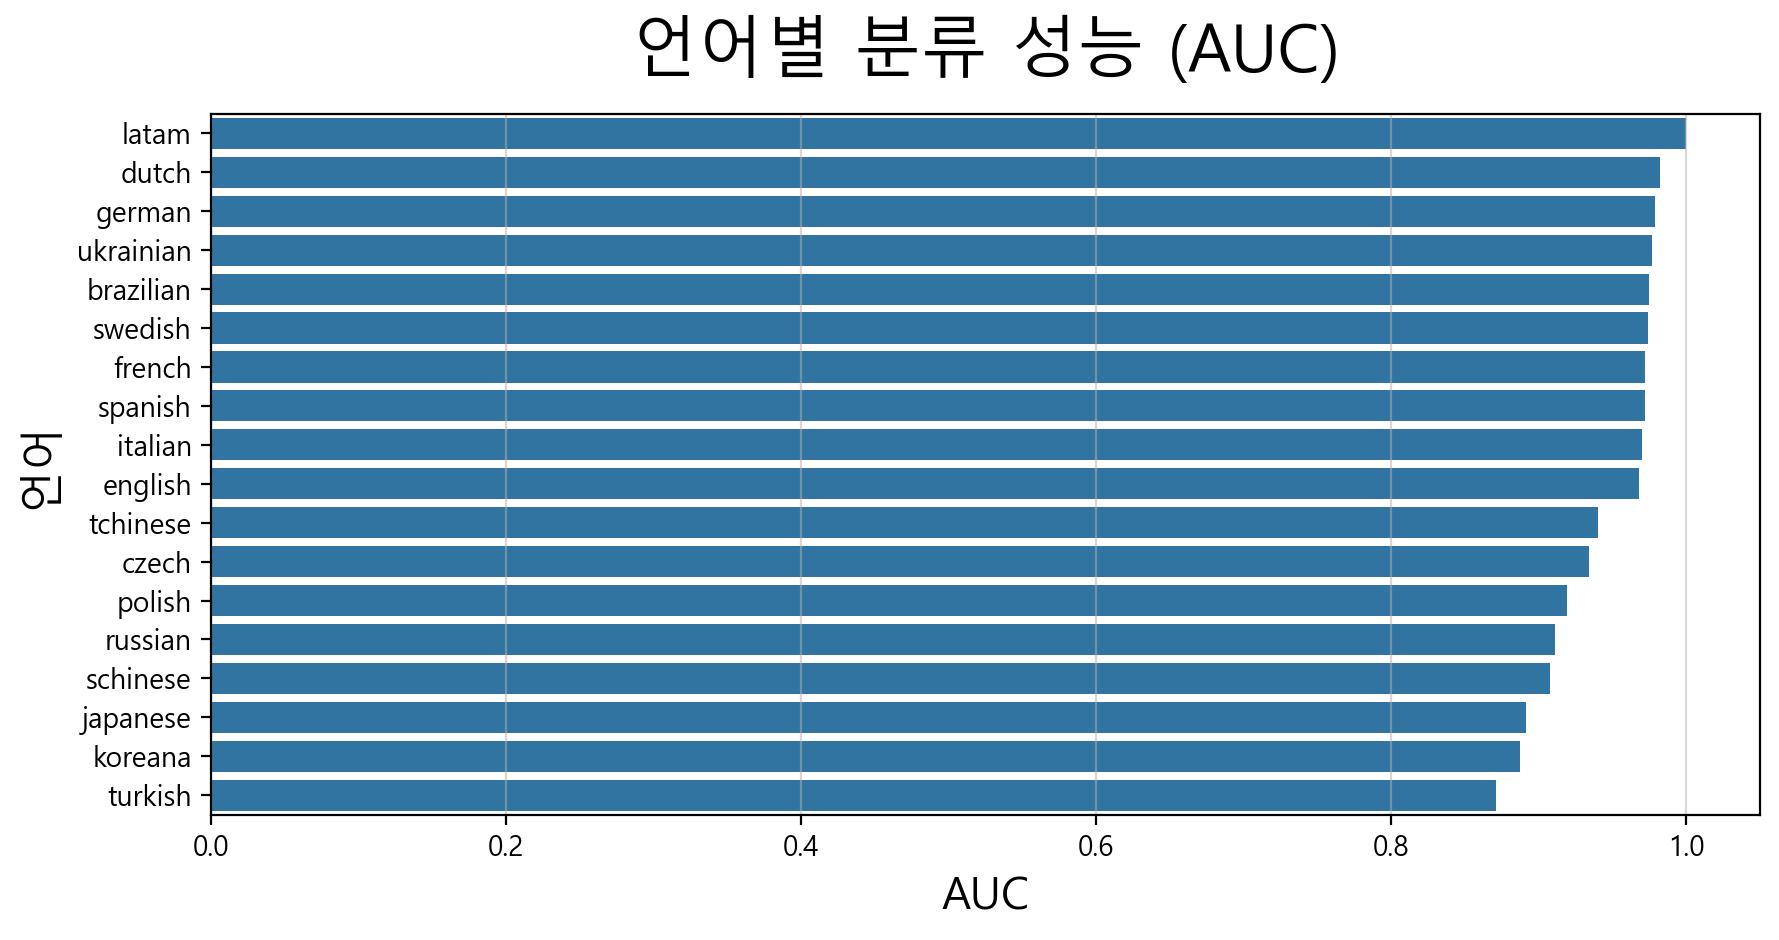

,n,긍정률,AUC,Acc,평균길이
bin,,,,,
~20,3081.0,0.649,0.937,0.869,9.654
20-50,2158.0,0.608,0.935,0.865,33.638
50-150,2948.0,0.594,0.962,0.891,90.776
150-500,2927.0,0.548,0.978,0.924,288.578
500+,3070.0,0.469,0.955,0.889,1662.114


In [ ]:
import matplotlib.pyplot as plt

# [보완] 로컬 환경(Windows) 한글 폰트 깨짐 방지 설정
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)

# 언어별 / 길이별 성능
d = df.iloc[te].copy()
d['p'] = p_main
d['y'] = y[te]

def perf(s):
    # s가 데이터프레임 서브셋으로 들어올 때의 처리
    y_true = s['y']
    y_pred_prob = s['p']
    
    # 클래스가 2개 이상일 때만 AUC 계산, 아니면 NaN
    auc_val = roc_auc_score(y_true, y_pred_prob) if len(np.unique(y_true)) > 1 else np.nan
    acc_val = accuracy_score(y_true, (y_pred_prob >= .5).astype(int))
    
    return pd.Series({
        'n': len(s), 
        '긍정률': y_true.mean(),
        'AUC': auc_val,
        'Acc': acc_val,
        '평균길이': s['len'].mean()
    })

cnt = d.language.value_counts()
target_languages = cnt[cnt >= 30].index

# [보완] Pandas 2.x 경고 방지를 위해 부모 컬럼에서 필요한 것만 그룹바이하고 include_groups=False 적용
lang_perf = (d[d.language.isin(target_languages)]
             .groupby('language', as_index=True)
             .apply(perf, include_groups=False)
             .sort_values('AUC', ascending=False))

display(lang_perf.round(3))

# 시각화 및 저장
hp.my_plot.barplot(data=lang_perf.reset_index(), x='AUC', y='language',
                   title='언어별 분류 성능 (AUC)', xlabel='AUC', ylabel='언어',
                   width=900, height=480, save_path='out/언어별_AUC.png')

# 길이별 구간 분석
d['bin'] = pd.cut(d['len'], [0, 20, 50, 150, 500, 10**9],
                  labels=['~20', '20-50', '50-150', '150-500', '500+'])

# [보완] 여기도 동일하게 include_groups=False 적용하여 안정성 확보
bin_perf = d.groupby('bin', observed=True).apply(perf, include_groups=False)
display(bin_perf.round(3))

,n,실제긍정률,평균예측
pb,,,
"(-0.001, 0.1]",3079,0.027,0.036
"(0.1, 0.3]",1796,0.138,0.183
"(0.3, 0.5]",1082,0.370,0.398
"(0.5, 0.7]",1181,0.594,0.606
"(0.7, 0.9]",1952,0.859,0.816
"(0.9, 1.0]",5094,0.982,0.968


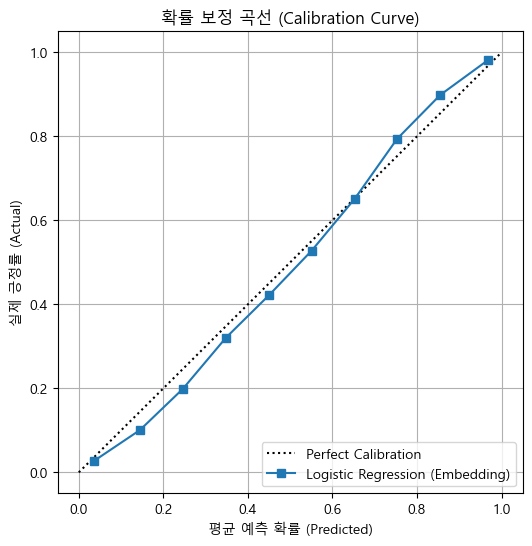

In [ ]:
from sklearn.calibration import calibration_curve

# 1. 구간 나누기 (include_lowest=True 추가로 p=0.0 값 누수 방지)
d['pb'] = pd.cut(d.p, [0, .1, .3, .5, .7, .9, 1.0], include_lowest=True)

# 2. 구간별 통계 테이블 출력
calibration_table = (d.groupby('pb', observed=True)
                      .agg(n=('y', 'size'), 
                           실제긍정률=('y', 'mean'), 
                           평균예측=('p', 'mean'))
                      .round(3))
display(calibration_table)


# 💡 [추천 보완] 확률 보정 시각화 (Calibration Curve)
plt.figure(figsize=(6, 6))

# 사이킷런 내장 함수로 10개 구간의 실제값/예측값 계산
true_prob, pred_prob = calibration_curve(d['y'], d['p'], n_bins=10, strategy='uniform')

# 완벽한 보정선 (대각선 y=x)
plt.plot([0, 1], [0, 1], "k:", label="Perfect Calibration")

# 우리 모델의 보정선
plt.plot(pred_prob, true_prob, "s-", label="Logistic Regression (Embedding)")

plt.ylabel("실제 긍정률 (Actual)")
plt.xlabel("평균 예측 확률 (Predicted)")
plt.title("확률 보정 곡선 (Calibration Curve)")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

In [ ]:
# 1. [보완] 로컬 환경에서 dataSets 폴더가 없을 경우를 대비한 자동 생성 코드
os.makedirs('dataSets', exist_ok=True)

# 2. 전체 데이터에 불만강도 부여 후 저장
# (clf 모델은 앞서 n_jobs=-1로 학습되었으므로 빠르게 연산됩니다.)
df['불만강도'] = 1 - clf.predict_proba(X)[:, 1]

# [보완] 다국어 및 한글 깨짐 방지를 위해 encoding='utf-8-sig' 추가
df[['recommendationid', '불만강도']].to_csv('Project3/불만강도.csv', index=False, encoding='utf-8-sig')

# 3. 스테이지별 불만율 및 불만강도 집계
# lambda 식 내부 연산을 가독성 있게 정리하고 100을 곱해 퍼센트화 유지
stage = df.groupby('stage_at_review').agg(
    리뷰수=('voted_up', 'size'),
    불만율=('voted_up', lambda x: (1 - x.mean()) * 100),
    불만강도=('불만강도', lambda x: x.mean() * 100)
).round(1)

display(stage)

,리뷰수,불만율,불만강도
stage_at_review,,,
0,2503,43.7,44.4
1,4260,57.5,54.1
2,30788,44.1,43.8
3,6539,39.7,40.4
4,4320,37.9,39.4
5,1945,41.2,41.3
6,2411,38.7,39.5
7,2338,41.7,42.1
8,18,44.4,50.3


In [ ]:
# 두 가지 불일치 세그먼트 — 연속 점수가 있어야 뽑을 수 있다
assert '불만강도' in df.columns, '앞 셀(불만강도 부여)을 먼저 실행하세요'

# 1. 원본 df에서 직접 다중 조건을 주어 SettingWithCopyWarning을 완벽히 방지합니다.
# [단발불평] 추천(True) + 불만강도 고득점(> 0.8)
단발불평 = df[(df.voted_up == True) & (df['불만강도'] > 0.8)]

# [애증] 추천(True) + 불만강도 중고득점(0.5 ~ 0.75) + 장문의 글(>= 200자)
애증 = df[(df.voted_up == True) & (df['불만강도'].between(0.5, 0.75)) & (df['len'] >= 200)]

# 2. 파이썬 표준 f-string을 사용하여 출력 가독성 개선
print(f"단발 불평형: {len(단발불평):,}건 / 애증형: {len(애증):,}건")

단발 불평형: 1,009건 / 애증형: 913건


In [ ]:
print("\n=== [단발불평형] 실제 리뷰 샘플 ===")
for i, row in 단발불평.head(3).iterrows():
    print(f"[{row['language']}] (불만강도: {row['불만강도']:.2f}) -> {row['review'].strip()[:100]}...")

print("\n=== [애증형] 실제 리뷰 샘플 ===")
for i, row in 애증.head(3).iterrows():
    print(f"[{row['language']}] (길이: {row['len']}자 / 불만강도: {row['불만강도']:.2f}) -> {row['review'].strip()[:100]}...")


=== [단발불평형] 실제 리뷰 샘플 ===
[koreana] (불만강도: 0.85) -> Star Faild...
[english] (불만강도: 0.85) -> Starfield, if Outer Worlds and Fallout had a baby and Star Citizen raised it. Lets talk about whats ...
[english] (불만강도: 0.83) -> Give me optimization...

=== [애증형] 실제 리뷰 샘플 ===
[english] (길이: 336자 / 불만강도: 0.64) -> Todd, no offense, but this is a good game. Update after actually playing it: Actually it was kind of...
[schinese] (길이: 595자 / 불만강도: 0.72) -> 2023年9月1日，由贝塞斯达游戏工作室制作，万众期待的太空冒险游戏《星空》上线Xbox Series X|S和PC平台。然而，这款被誉为“太空版《上古卷轴》”的游戏却让玩家们大失所望。《星空》充斥着...
[schinese] (길이: 653자 / 불만강도: 0.64) -> ⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿ ⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⠿⠛⠛⠛⠉⠉⠛⠻⠿⢿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿ ⣿⣿⣿⣿⣿⣿⣿⠟⠋⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⠉⢿⣿⣿⣿⣿⣿⣿⣿ ⣿⣿⣿⣿⣿⣿⠃...
